**OBJECTIVE**

To analyze thee pokemon characteristics and build a machine learning model that can predict a pokemons primary battle type1 based on its physical attributes and combat statistics.

***understanding the problem:***



This is a supervised
.machine learning classification problem.

Target is primary battle type(type 1)
Input features are physical attributes and combat stats: height, weight, HP, attack, and defense.

Task 1 : Data understanding & Exploration

import the libraries required

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



*   Load the dataset



In [3]:
#Read the uploaded CSV file into a pandas DataFrame
pk = pd.read_csv('/content/drive/MyDrive/exit exam/G2.csv')

* inspect its *structures

In [11]:
#display the first five rows to preview the data
print(pk.head())

#Check each column's data type and count of non-missing values
print(pk.info())



#List the column names
print(pk.columns)

#finding number of columns and rows
print(pk.shape)

   id        name  height_dm  weight_hg  base_experience type_1  type_2  hp  \
0   1   bulbasaur          7         69             64.0  grass  poison  45   
1   2     ivysaur         10        130            142.0  grass  poison  60   
2   3    venusaur         20       1000            236.0  grass  poison  80   
3   4  charmander          6         85             62.0   fire     NaN  39   
4   5  charmeleon         11        190            142.0   fire     NaN  58   

   attack  defense  
0      49       49  
1      62       63  
2      82       83  
3      52       43  
4      64       58  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1351 non-null   int64  
 1   name             1351 non-null   object 
 2   height_dm        1351 non-null   int64  
 3   weight_hg        1351 non-null   int64  
 4   base_experi

* identify numerical and categorical features

In [9]:
num_cols = pk.select_dtypes(include="number").columns.tolist()
cat_cols = pk.select_dtypes(exclude="number").columns.tolist()
print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['id', 'height_dm', 'weight_hg', 'base_experience', 'hp', 'attack', 'defense']
Categorical: ['name', 'type_1', 'type_2']


In [12]:
#check for missing values
print(pk.isnull().sum())

#check for duplicates

print(pk.duplicated().sum())

id                   0
name                 0
height_dm            0
weight_hg            0
base_experience     49
type_1               0
type_2             586
hp                   0
attack               0
defense              0
dtype: int64
0


* generate summary statistics

In [14]:
#Summarize numerical columns with count, mean, standard deviation, and range
print(pk.describe())

                 id    height_dm     weight_hg  base_experience           hp  \
count   1351.000000  1351.000000   1351.000000      1302.000000  1351.000000   
mean    2841.692080    20.443375    991.059956       161.943932    71.673575   
std     4139.019112    53.238467   1953.115812        82.532554    26.827529   
min        1.000000     1.000000      0.000000        36.000000     1.000000   
25%      338.500000     6.000000     94.500000        71.000000    55.000000   
50%      676.000000    11.000000    326.000000       165.000000    70.000000   
75%     1013.500000    17.000000    853.500000       222.500000    85.000000   
max    10326.000000  1000.000000  10000.000000       608.000000   255.000000   

            attack      defense  
count  1351.000000  1351.000000  
mean     82.757957    76.193930  
std      32.351906    30.712902  
min       5.000000     5.000000  
25%      60.000000    55.000000  
50%      80.000000    70.000000  
75%     102.500000    95.000000  
max    

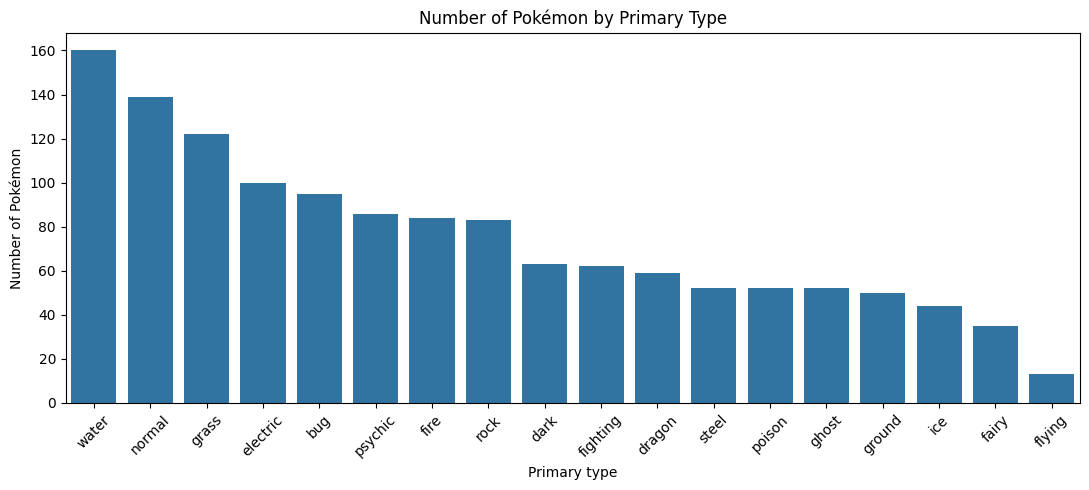

In [28]:
#visualise the diustribution


# Numerical attributes for exploration
features = ["height_dm", "weight_hg", "hp", "attack", "defense"]
type_order = pk["type_1"].value_counts().index

# 1. Count of Pokémon by primary type
plt.figure(figsize=(11, 5))
sns.countplot(data=pk, x="type_1", order=type_order)
plt.title("Number of Pokémon by Primary Type")
plt.xlabel("Primary type")
plt.ylabel("Number of Pokémon")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




Q1) most frequent type is : water

In [19]:
type_counts = pk["type_1"].value_counts()
print(type_counts)

type_1
water       160
normal      139
grass       122
electric    100
bug          95
psychic      86
fire         84
rock         83
dark         63
fighting     62
dragon       59
steel        52
poison       52
ghost        52
ground       50
ice          44
fairy        35
flying       13
Name: count, dtype: int64


  Q2) weight_hg is likely to show the greatest raw variation,

Q3)initial observations:

* Height and weight distributions are strongly right-skewed.

* The physical and combat features have positive correlations

* Primary types are unevenly represented. Water appears to be the most frequent primary type, with about 160 Pokémon, while flying is the least frequent, with about 13.

Task2 : Data Preprocessing

In [ ]:
#handle the missing values


base_experience is a numeric column, but it represents experience earned, not a physical attribute or one of the combat stats.


so there is no missing values to handle

In [20]:
# List each primary type
print("Unique type_1 values:")
print(sorted(pk["type_1"].dropna().unique()))

# Count Pokémon in each primary type
print("\nCount by primary type:")
print(pk["type_1"].value_counts())

Unique type_1 values:
['bug', 'dark', 'dragon', 'electric', 'fairy', 'fighting', 'fire', 'flying', 'ghost', 'grass', 'ground', 'ice', 'normal', 'poison', 'psychic', 'rock', 'steel', 'water']

Count by primary type:
type_1
water       160
normal      139
grass       122
electric    100
bug          95
psychic      86
fire         84
rock         83
dark         63
fighting     62
dragon       59
steel        52
poison       52
ghost        52
ground       50
ice          44
fairy        35
flying       13
Name: count, dtype: int64


In [21]:
pk['type_1'].value_counts()

,count
type_1,
water,160
normal,139
grass,122
electric,100
bug,95
psychic,86
fire,84
rock,83
dark,63


In [26]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Use physical and combat attributes as input features
features = ["height_dm", "weight_hg", "hp", "attack", "defense"]
X = pk[features].copy()

# The primary type is the categorical target
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(pk["type_1"])

# Split before fitting the imputer or scaler.
# Stratification preserves the type proportions in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# Handle missing numerical feature values using training-set medians
imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Scale features for models such as Logistic Regression, SVM, or KNN
scaler = StandardScaler()
X_train_prepared = scaler.fit_transform(X_train_imputed)
X_test_prepared = scaler.transform(X_test_imputed)

print("Prepared training features:", X_train_prepared.shape)
print("Prepared test features:", X_test_prepared.shape)
print("Encoded target classes:", label_encoder.classes_)

Prepared training features: (1080, 5)
Prepared test features: (271, 5)
Encoded target classes: ['bug' 'dark' 'dragon' 'electric' 'fairy' 'fighting' 'fire' 'flying'
 'ghost' 'grass' 'ground' 'ice' 'normal' 'poison' 'psychic' 'rock' 'steel'
 'water']


Q1)Preprocessing prepares the data so a machine-learning model can use it reliably.

Missing values: Many models cannot train with missing feature values. Imputation can fill them

Encoding: A model needs categorical labels represented in a form it supports. your input features are already numeric.

Scaling: Scaling puts features on comparable scales.

Train/test separation: Fit preprocessing steps on training data only, then apply them to test data. This prevents information from the test set leaking into traininG, called as data leakage

Q2) I didn’t handle type_2 missing values in the model-preparation code.
I excluded type_2 because it isn’t an input feature for your current model, which uses physical and combat stats to predict type_1.

ype_2 should be excluded as it is another type label and could give the model information closely related to the type_1 target

Task3 : Exploratory Data Analysis

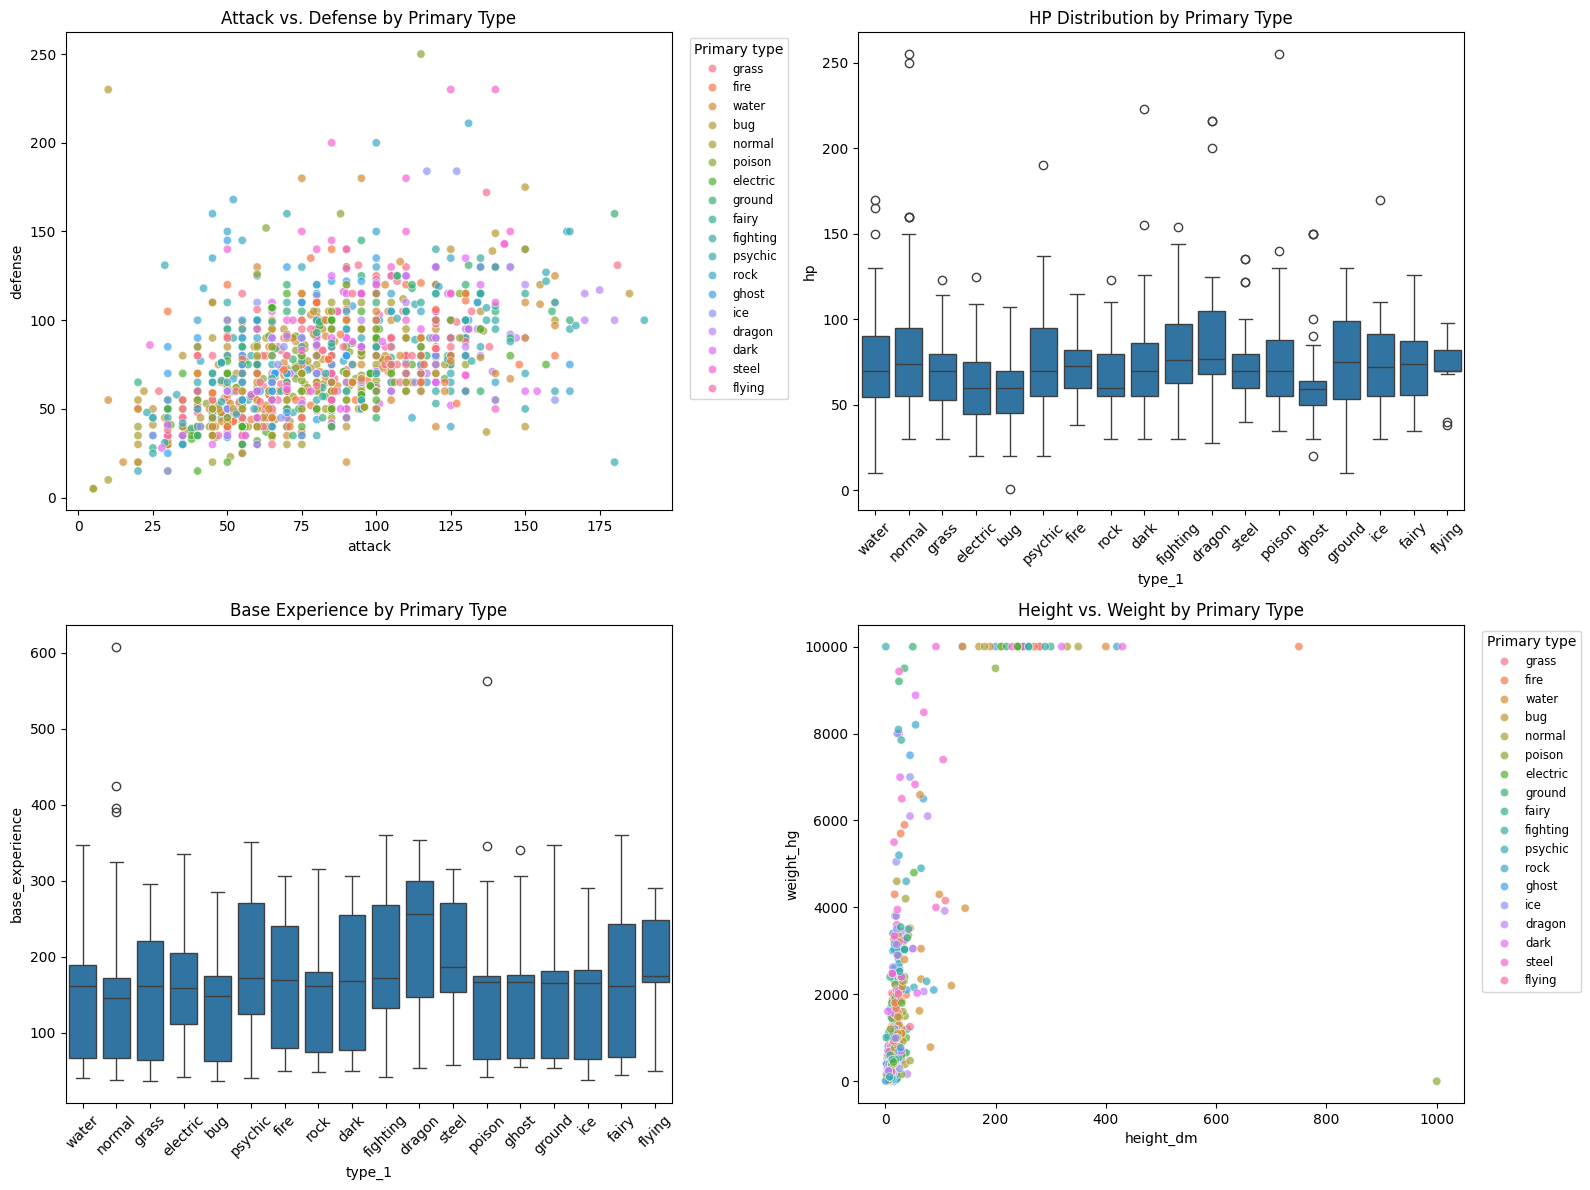

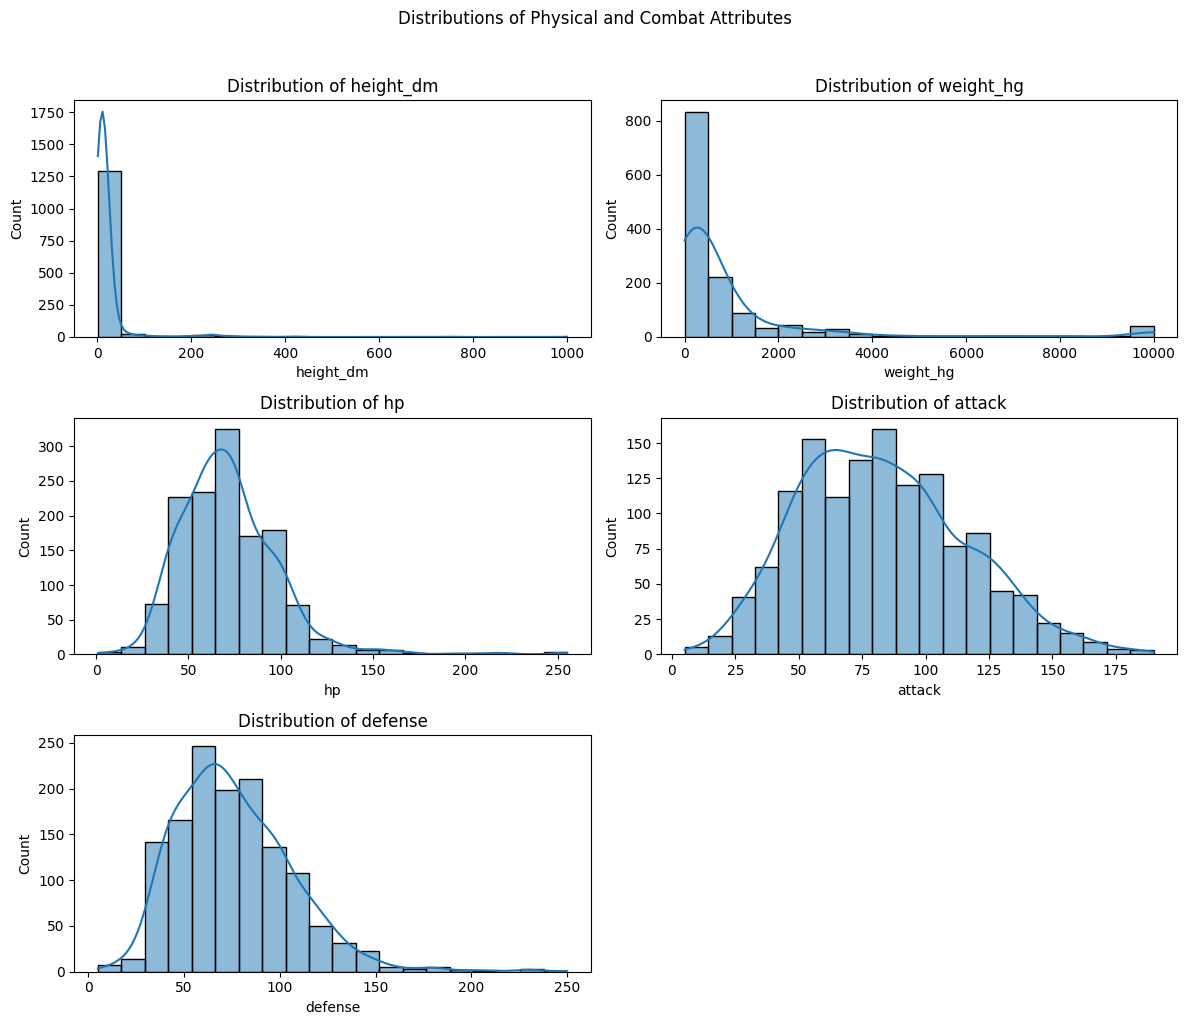

<Figure size 640x480 with 0 Axes>

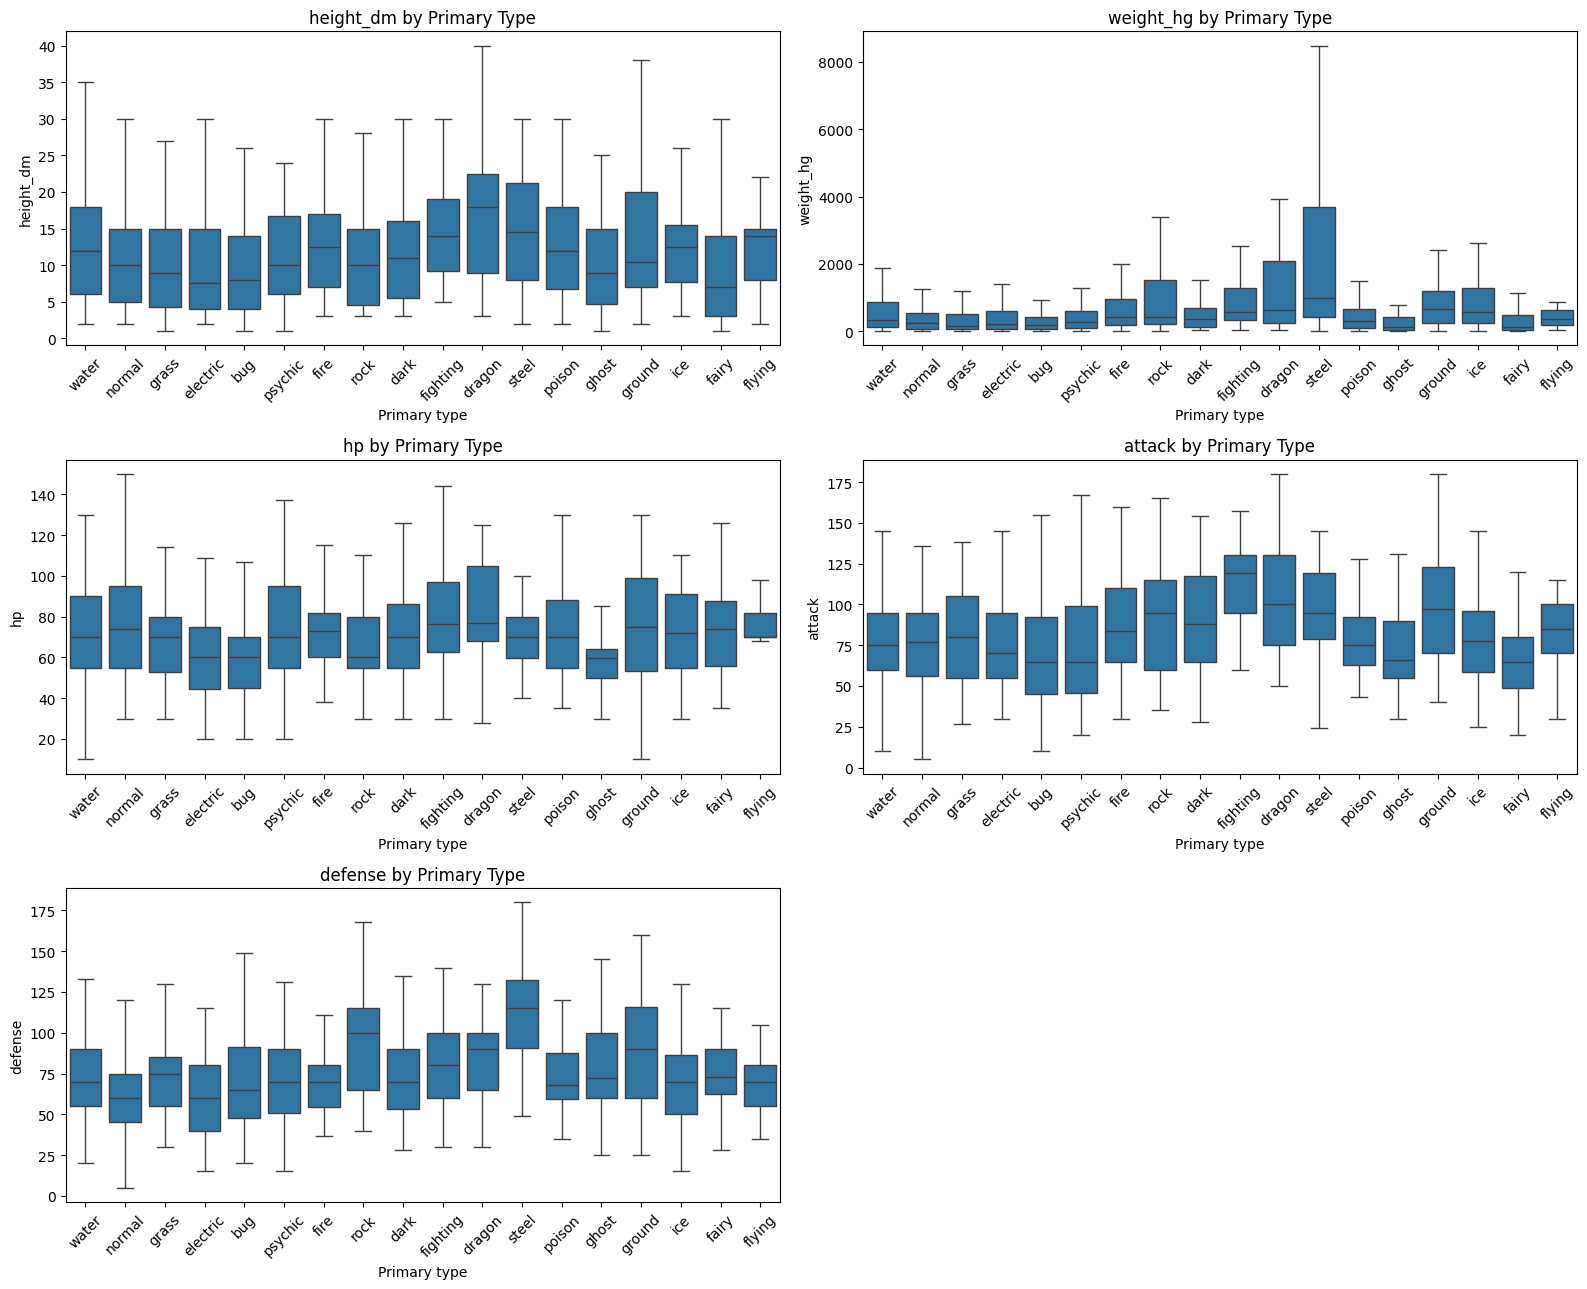

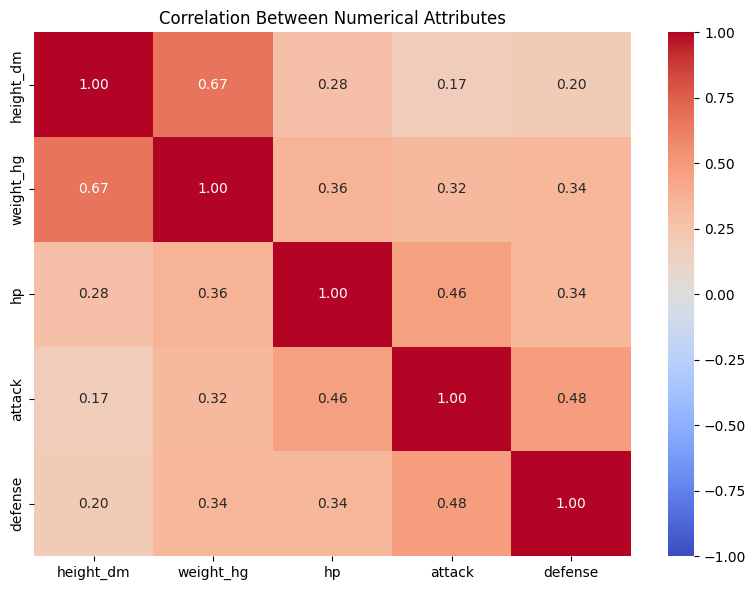

In [29]:

# Order types by frequency for consistent boxplot axes
type_order = pk["type_1"].value_counts().index

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Attack vs. Defense, colored by primary type
sns.scatterplot(
    data=pk,
    x="attack",
    y="defense",
    hue="type_1",
    alpha=0.7,
    ax=axes[0, 0],
)
axes[0, 0].set_title("Attack vs. Defense by Primary Type")
axes[0, 0].legend(
    title="Primary type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize="small",
)

# 2. HP distribution across primary types
sns.boxplot(
    data=pk,
    x="type_1",
    y="hp",
    order=type_order,
    ax=axes[0, 1],
)
axes[0, 1].set_title("HP Distribution by Primary Type")
axes[0, 1].tick_params(axis="x", rotation=45)

# 3. Base experience by primary type
# Rows with missing base_experience are omitted from this plot.
sns.boxplot(
    data=pk,
    x="type_1",
    y="base_experience",
    order=type_order,
    ax=axes[1, 0],
)
axes[1, 0].set_title("Base Experience by Primary Type")
axes[1, 0].tick_params(axis="x", rotation=45)

# 4. Height vs. Weight, colored by primary type
sns.scatterplot(
    data=pk,
    x="height_dm",
    y="weight_hg",
    hue="type_1",
    alpha=0.7,
    ax=axes[1, 1],
)
axes[1, 1].set_title("Height vs. Weight by Primary Type")
axes[1, 1].legend(
    title="Primary type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize="small",
)

plt.tight_layout()
plt.show()

# 2. Distributions of numerical attributes

# Create one subplot for each feature
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
axes = axes.flatten()

# Plot a histogram with a KDE curve for each feature
for ax, feature in zip(axes, features):
    sns.histplot(
        data=pk,
        x=feature,
        bins=20,
        kde=True,
        edgecolor="black",
        ax=ax,
    )
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Count")

# Hide the unused subplot
axes[-1].set_visible(False)

plt.suptitle("Distributions of Physical and Combat Attributes", y=1.02)
plt.tight_layout()
plt.show()

# Hide the unused sixth plot
axes[-1].set_visible(False)

fig.suptitle("Distributions of Physical and Combat Attributes")
plt.tight_layout()
plt.show()

# 3. Compare each numerical attribute across primary types
fig, axes = plt.subplots(3, 2, figsize=(16, 13))
axes = axes.flatten()

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=pk,
        x="type_1",
        y=feature,
        order=type_order,
        showfliers=False,
        ax=ax,
    )
    ax.set_title(f"{feature} by Primary Type")
    ax.set_xlabel("Primary type")
    ax.tick_params(axis="x", rotation=45)

# Hide the unused sixth subplot
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

# 4. Correlation between numerical attributes
plt.figure(figsize=(8, 6))
sns.heatmap(
    pk[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
)
plt.title("Correlation Between Numerical Attributes")
plt.tight_layout()
plt.show()


Q1) Fighting-type Pokémon appear to have the highest typical attack

Q2)  scatter plot and correlation heatmap show a positive relationship between height and weight.Pokémon that are taller generally tend to be heavieR.

Q3) attack appears to be the most useful feature for distinguishing primary types

Task4 : Machine Learning Model

Model 1 — Logistic Regression

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
# Pipeline: impute missing numeric values, scale features, then train Logistic Regression
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=3000)),
])

# Train the model and make predictions
logistic_model.fit(X_train, y_train)
y_pred_logistic = logistic_model.predict(X_test)

# Evaluate Model 1
print("Model 1: Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, y_pred_logistic), 3))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_test, y_pred_logistic), 3
))
print("Macro F1:", round(
    f1_score(y_test, y_pred_logistic, average="macro", zero_division=0), 3
))

print("\nClassification report:")
print(classification_report(y_test, y_pred_logistic, zero_division=0))

Model 1: Logistic Regression
Accuracy: 0.155
Balanced accuracy: 0.106
Macro F1: 0.088

Classification report:
              precision    recall  f1-score   support

           0       0.05      0.05      0.05        19
           1       0.00      0.00      0.00        13
           2       0.25      0.17      0.20        12
           3       0.26      0.35      0.30        20
           4       0.00      0.00      0.00         7
           5       0.07      0.08      0.08        12
           6       0.00      0.00      0.00        17
           7       0.00      0.00      0.00         3
           8       0.00      0.00      0.00        10
           9       0.12      0.08      0.10        25
          10       0.00      0.00      0.00        10
          11       0.00      0.00      0.00         9
          12       0.19      0.36      0.25        28
          13       0.00      0.00      0.00        10
          14       0.00      0.00      0.00        17
          15       0.12  

Model 2 — Decision Tree

In [32]:
from sklearn.tree import DecisionTreeClassifier
# Build a Decision Tree model
decision_tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42,
    )),
])

# Train and predict using the same split as Model 1
decision_tree_model.fit(X_train, y_train)
y_pred_tree = decision_tree_model.predict(X_test)

# Evaluate Model 2
print("Model 2: Decision Tree")
print("Accuracy:", round(accuracy_score(y_test, y_pred_tree), 3))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_test, y_pred_tree), 3
))
print("Macro F1:", round(
    f1_score(y_test, y_pred_tree, average="macro", zero_division=0), 3
))

# Show Pokémon type names instead of encoded numbers, if label_encoder was used
if "label_encoder" in globals():
    print("\nClassification report:")
    print(classification_report(
        y_test,
        y_pred_tree,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0,
    ))
else:
    print("\nClassification report:")
    print(classification_report(y_test, y_pred_tree, zero_division=0))

Model 2: Decision Tree
Accuracy: 0.221
Balanced accuracy: 0.186
Macro F1: 0.187

Classification report:
              precision    recall  f1-score   support

         bug       0.32      0.37      0.34        19
        dark       0.00      0.00      0.00        13
      dragon       0.21      0.25      0.23        12
    electric       0.39      0.35      0.37        20
       fairy       0.00      0.00      0.00         7
    fighting       0.29      0.17      0.21        12
        fire       0.15      0.24      0.19        17
      flying       0.00      0.00      0.00         3
       ghost       0.25      0.20      0.22        10
       grass       0.35      0.24      0.29        25
      ground       0.08      0.10      0.09        10
         ice       0.08      0.11      0.09         9
      normal       0.38      0.29      0.33        28
      poison       0.00      0.00      0.00        10
     psychic       0.29      0.24      0.26        17
        rock       0.22      0.

Model 3: Random Forest

In [33]:
from sklearn.ensemble import RandomForestClassifier
# Build a Random Forest model
random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )),
])

# Train and predict using the same split as Models 1 and 2
random_forest_model.fit(X_train, y_train)
y_pred_forest = random_forest_model.predict(X_test)

# Evaluate Model 3
print("Model 3: Random Forest")
print("Accuracy:", round(accuracy_score(y_test, y_pred_forest), 3))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_test, y_pred_forest), 3
))
print("Macro F1:", round(
    f1_score(y_test, y_pred_forest, average="macro", zero_division=0), 3
))

# Display type names when y was label-encoded
if "label_encoder" in globals():
    print("\nClassification report:")
    print(classification_report(
        y_test,
        y_pred_forest,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0,
    ))
else:
    print("\nClassification report:")
    print(classification_report(y_test, y_pred_forest, zero_division=0))

Model 3: Random Forest
Accuracy: 0.28
Balanced accuracy: 0.241
Macro F1: 0.246

Classification report:
              precision    recall  f1-score   support

         bug       0.27      0.37      0.31        19
        dark       0.33      0.23      0.27        13
      dragon       0.29      0.33      0.31        12
    electric       0.39      0.35      0.37        20
       fairy       0.25      0.14      0.18         7
    fighting       0.08      0.08      0.08        12
        fire       0.30      0.35      0.32        17
      flying       0.00      0.00      0.00         3
       ghost       0.25      0.20      0.22        10
       grass       0.35      0.32      0.33        25
      ground       0.40      0.20      0.27        10
         ice       0.00      0.00      0.00         9
      normal       0.33      0.43      0.38        28
      poison       0.33      0.10      0.15        10
     psychic       0.43      0.35      0.39        17
        rock       0.32      0.3

Model 4: Support Vector Machine (SVM)

In [35]:
from sklearn.svm import SVC
# Build an SVM model
svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced",
    )),
])

# Train and predict using the same split as the previous models
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)

# Evaluate Model 4
print("Model 4: Support Vector Machine")
print("Accuracy:", round(accuracy_score(y_test, y_pred_svm), 3))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_test, y_pred_svm), 3
))
print("Macro F1:", round(
    f1_score(y_test, y_pred_svm, average="macro", zero_division=0), 3
))

# Show Pokémon type names if the target was label-encoded
if "label_encoder" in globals():
    print("\nClassification report:")
    print(classification_report(
        y_test,
        y_pred_svm,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0,
    ))
else:
    print("\nClassification report:")
    print(classification_report(y_test, y_pred_svm, zero_division=0))

Model 4: Support Vector Machine
Accuracy: 0.125
Balanced accuracy: 0.142
Macro F1: 0.108

Classification report:
              precision    recall  f1-score   support

         bug       0.15      0.21      0.18        19
        dark       0.33      0.08      0.12        13
      dragon       0.25      0.25      0.25        12
    electric       0.19      0.30      0.23        20
       fairy       0.06      0.29      0.10         7
    fighting       0.11      0.33      0.17        12
        fire       0.00      0.00      0.00        17
      flying       0.00      0.00      0.00         3
       ghost       0.29      0.40      0.33        10
       grass       0.00      0.00      0.00        25
      ground       0.00      0.00      0.00        10
         ice       0.00      0.00      0.00         9
      normal       0.29      0.14      0.19        28
      poison       0.00      0.00      0.00        10
     psychic       0.00      0.00      0.00        17
        rock       0.2

,Model,Accuracy,Balanced accuracy,Macro F1
2,Random Forest,0.280,0.241,0.246
1,Decision Tree,0.221,0.186,0.187
3,SVM,0.125,0.142,0.108
0,Logistic Regression,0.155,0.106,0.088


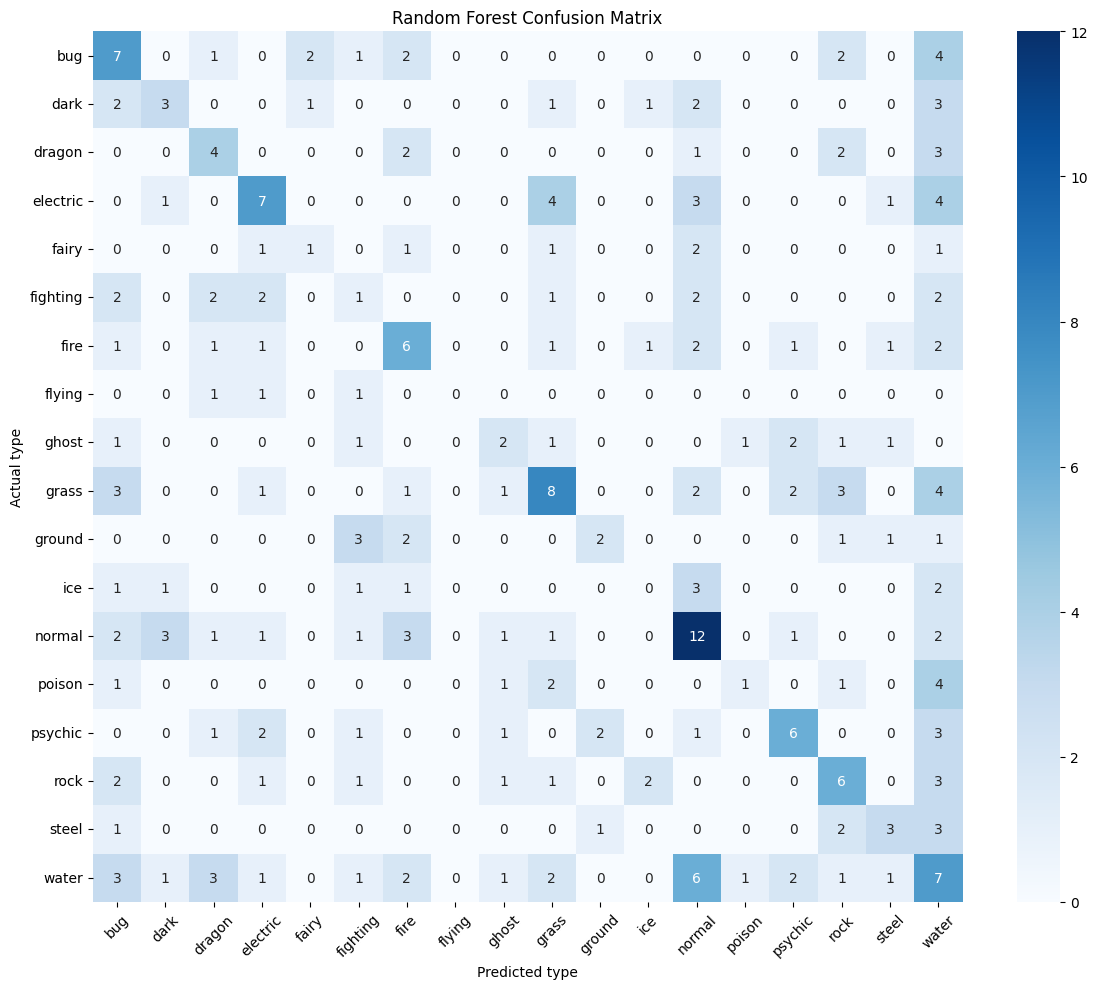

Random Forest feature importance:


,importance
weight_hg,0.239286
defense,0.197930
attack,0.196679
hp,0.195669
height_dm,0.170435


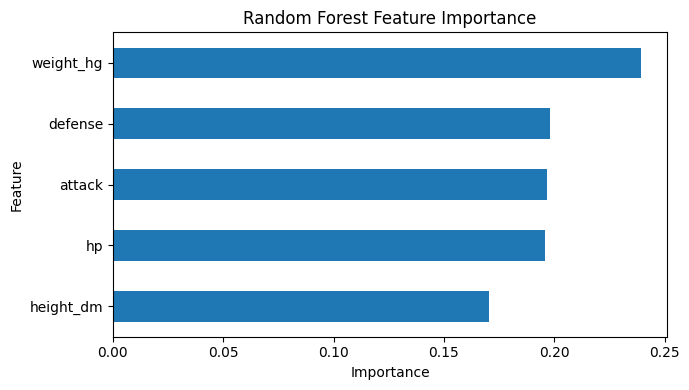

In [37]:
from sklearn.metrics import confusion_matrix

# Compare the four models using the scores you reported
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
    ],
    "Accuracy": [0.155, 0.221, 0.280, 0.125],
    "Balanced accuracy": [0.106, 0.186, 0.241, 0.142],
    "Macro F1": [0.088, 0.187, 0.246, 0.108],
})

display(results.sort_values("Macro F1", ascending=False))

# Create a confusion matrix for Random Forest
class_ids = np.arange(len(label_encoder.classes_))
cm = confusion_matrix(y_test, y_pred_forest, labels=class_ids)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted type")
plt.ylabel("Actual type")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Extract and display Random Forest feature importance
rf_classifier = random_forest_model.named_steps["classifier"]

importance = pd.Series(
    rf_classifier.feature_importances_,
    index=features,
).sort_values(ascending=False)

print("Random Forest feature importance:")
display(importance.to_frame(name="importance"))

importance.sort_values().plot(kind="barh", figsize=(7, 4))
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Q1) Best model is Random Forest with accuracy 0.280, balanced accuracy 0.241, macro F1 0.246

  Q2) Water has the most misclassified test Pokémon by count 25 of 32 were predicted as another type

Q3) Flying had only 3 test Pokémon and all 3 were misclassified.
Fairy had 7 with only 1 correctly classified.

In [40]:
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.pipeline import Pipeline

# Set the input features and target
features = ["height_dm", "weight_hg", "hp", "attack", "defense"]
X = pk[features].copy()
y = pk["type_1"].astype(str).str.strip().str.lower()

# Recreate the same stratified train/test split for a fair comparison
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# Keep imputation and the classifier together in a pipeline
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1,
    )),
])

# Settings to explore
param_distributions = {
    "classifier__n_estimators": [200, 300, 500],
    "classifier__max_depth": [None, 10, 20, 30],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", 0.8],
}

# Use stratified cross-validation to retain type proportions in each fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=25,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

# Tune using training data only
search.fit(X_train, y_train)

best_model = search.best_estimator_
print("Best cross-validation macro F1:", round(search.best_score_, 3))
print("Best settings:", search.best_params_)

# Evaluate the selected model on the held-out test set
y_pred_tuned = best_model.predict(X_test)

print("\nTuned Random Forest — test results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 3))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_test, y_pred_tuned), 3
))
print("Macro F1:", round(
    f1_score(y_test, y_pred_tuned, average="macro", zero_division=0), 3
))

print("\nClassification report:")
print(classification_report(y_test, y_pred_tuned, zero_division=0))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best cross-validation macro F1: 0.205
Best settings: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 0.8, 'classifier__max_depth': 30}

Tuned Random Forest — test results
Accuracy: 0.28
Balanced accuracy: 0.242
Macro F1: 0.242

Classification report:
              precision    recall  f1-score   support

         bug       0.28      0.37      0.32        19
        dark       0.25      0.23      0.24        13
      dragon       0.17      0.25      0.20        12
    electric       0.39      0.35      0.37        20
       fairy       0.17      0.14      0.15         7
    fighting       0.11      0.08      0.10        12
        fire       0.29      0.35      0.32        17
      flying       0.00      0.00      0.00         3
       ghost       0.20      0.20      0.20        10
       grass       0.36      0.32      0.34        25
      g

final model selection

In [41]:
import joblib
# Use the same input features and target as in model evaluation
features = ["height_dm", "weight_hg", "hp", "attack", "defense"]
X_full = pk[features].copy()
y_full = pk["type_1"].astype(str).str.strip().str.lower()

# Ensure every training row has a target label
if y_full.isna().any():
    raise ValueError("Some rows have no type_1 label. Remove those rows before fitting.")

# Recreate the selected Random Forest pipeline
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )),
])

# Fit using all labeled data
final_model.fit(X_full, y_full)

# Save the fitted pipeline
model_path = "pokemon_type_model.joblib"
joblib.dump(final_model, model_path)

print(f"Saved model: {model_path}")
print(f"Training records: {len(X_full)}")
print(f"Required input columns: {features}")

Saved model: pokemon_type_model.joblib
Training records: 1351
Required input columns: ['height_dm', 'weight_hg', 'hp', 'attack', 'defense']


In [43]:
from google.colab import drive
import os
import joblib

drive.mount("/content/drive")

save_folder = "/content/drive/MyDrive/exit exam/pokemon_flask_app"


os.makedirs(save_folder, exist_ok=True)

model_path = os.path.join(save_folder, "pokemon_type_model.joblib")
joblib.dump(final_model, model_path)

print("Model saved successfully:", model_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved successfully: /content/drive/MyDrive/exit exam/pokemon_flask_app/pokemon_type_model.joblib


In [45]:
from google.colab import files

files.download('/content/drive/MyDrive/exit exam/pokemon_flask_app')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Q1) For players: Enter height, weight, HP, attack, and defense to see which primary type the model predicts. It could be a fun guessing game or help players explore how stats vary across types.


For game developers: Use it to explore patterns in an existing Pokémon dataset, test prototype character stats or identify designs whose assigned type seems unusual relative to their stats.

Q2) Modest performance: Your selected Random Forest achieved 28% test accuracy and 0.246 macro F1, so many predictions will be incorrect.

Uneven type counts: The dataset contains far fewer examples of some types than others. Predictions for rare types may be especially unreliable
 for example, the test set had only 3 Flying Pokémon.

Limited input attributes: The model uses only height, weight, HP, attack, and defense. It leaves out other potentially relevant characteristics and does not capture appearance, abilities, lore, or design intent.